# Was the powerplay situationally safer, or just luckier?

**The question, given the season contrasts.** The powerplay six rate rose about 40% with a wicket rate that did not measurably change. That pairing is the project's headline, and it has a loophole: the powerplay wicket rate could have stayed flat because the *situations* got safer (more chases with easy targets, different bowlers, more left-handers), rather than because the extra aggression carried no cost. This notebook builds an expected-wicket model from pre-ball situation only and asks whether the expected powerplay wicket rate changed between seasons. If it did not, the situational loophole closes.

**What this notebook does.**
1. Builds strictly pre-ball features (over, wickets down, balls remaining, chase flag, required rate, batter hand; a second variant adds pace and spin indicators) and audits them for leakage, including by injecting a leaky column to show the audit catches it.
2. Fits two models through the identical nested, match-grouped cross-validation with calibration per phase: a gradient booster and a logistic baseline. The better calibrated one carries the contrast; the other is the robustness check.
3. Reports the season change in expected powerplay wicket rate against the actual change, with an equivalence verdict against a pre-stated smallest effect (0.3 wickets per powerplay).
4. Adds model uncertainty by refitting the whole pipeline on resampled seasons.
5. Decomposes the small expected change into feature contributions, so the null is explained rather than stated.
6. Asks the shot-level question the situation model cannot: did an aggressive shot become costlier in wickets between seasons?

**How to read this notebook.** *xW* is the probability of a wicket on a ball given only what was known before it was bowled. *Out-of-fold* means every ball's xW comes from a model that never saw that ball's match, so the contrast is not circular. *Calibration* means that among balls given xW of 5%, about 5% produced a wicket; Brier score and log-loss measure it (lower is better), and AUC is reported only as a leakage alarm (a situation-only model should be modest; a high value means a feature encodes the outcome). A *leakage audit* refuses any feature that describes the ball's own result.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Settings come from `[expected_wickets]`; the refit cell is the slow one. Code lives in `scripts/expected_wickets/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from expected_wickets import xw_analysis as xa, xw_model as xm
from expected_wickets.xw_features import (build_xw_features, assert_whitelist_only, leakage_tripwire,
                                          legal_aligned_column, FEATURE_VARIANTS, WHITELIST)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "expected_wickets"
SEED = settings.seed(ANALYSIS)
CFG = settings.section("expected_wickets")
N_ITER = settings.n_resamples
N_REFITS = int(CFG["model_refit_resamples"])
PRODUCER = "expected_wickets.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  refits={N_REFITS}  refit_n_jobs={CFG['refit_n_jobs']}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  refits=500  refit_n_jobs=4


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  seasons={sorted(df['year'].unique())}")
EXTRA = {"expected_wickets": CFG, "n_resamples": N_ITER, "fixture": USING_FIXTURE,
         "sesoi_per_ball": settings.section("sesoi")["expected_wickets_per_ball"]}

rows=34,967  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Features and the leakage audit

The feature matrix on legal deliveries, rebuilt inside each innings as cumulative-minus-current so a ball's own outcome can never enter its features; the provided running totals are not used because several are stated after the ball. Then: the NaN share of `required_rate` by innings (a first innings has no target), the whitelist assertion per variant, the tripwire AUC, and the adversarial injection of the ball's own `score`.

In [3]:
data = build_xw_features(df)
print("X shape:", data.X.shape, "| features:", list(data.X.columns))
print("wicket base rate (legal balls):", round(float(data.y.mean()), 4))
print("required_rate NaN share  inns1:", round(float(np.isnan(data.X['required_rate'][data.meta.inns == 1]).mean()), 3),
      "| inns2:", round(float(np.isnan(data.X['required_rate'][data.meta.inns == 2]).mean()), 3))
for variant, features in FEATURE_VARIANTS.items():
    assert_whitelist_only(data.X[features], features)
    print(variant, leakage_tripwire(data.X[features], data.y, data.groups, seed=SEED))
X_leak = data.X.assign(score=legal_aligned_column(df, "score").values)
try:
    assert_whitelist_only(X_leak)
    print("audit MISSED the leak")
except AssertionError as e:
    print("audit correctly refused:", str(e)[:80], "...")
print("leaked tripwire:", leakage_tripwire(X_leak, data.y, data.groups, seed=SEED))
data.X.head()

X shape: (33437, 8) | features: ['over_num', 'inns_wkts', 'inns_balls_rem', 'is_chase', 'required_rate', 'bat_is_lhb', 'bowl_is_pace', 'bowl_is_spin']
wicket base rate (legal balls): 0.0535
required_rate NaN share  inns1: 1.0 | inns2: 0.0
situation {'oof_auc': 0.5869854434978165, 'base_rate': 0.05350360379220624, 'alarm': False, 'verdict': 'modest AUC, consistent with situation-only'}
situation_bowler {'oof_auc': 0.5858440451873911, 'base_rate': 0.05350360379220624, 'alarm': False, 'verdict': 'modest AUC, consistent with situation-only'}
audit correctly refused: xW feature audit failed -- leakage columns present: ['score']; non-whitelist col ...
leaked tripwire: {'oof_auc': 0.8910382058286767, 'base_rate': 0.05350360379220624, 'alarm': True, 'verdict': 'SUSPICIOUS - inspect for leakage'}


,over_num,inns_wkts,inns_balls_rem,is_chase,required_rate,bat_is_lhb,bowl_is_pace,bowl_is_spin
0,1,0.0,120.0,0.0,NaN,1.0,1.0,0.0
1,1,0.0,119.0,0.0,NaN,1.0,1.0,0.0
2,1,0.0,118.0,0.0,NaN,0.0,1.0,0.0
3,1,0.0,117.0,0.0,NaN,0.0,1.0,0.0
4,1,0.0,116.0,0.0,NaN,1.0,1.0,0.0


**Found.** 33,437 legal balls at a 5.35% wicket rate. Tripwire AUC 0.59 for both variants, consistent with situation only; injecting the ball's own runs is refused by the audit and would lift the AUC to 0.89, so the alarm works.

## Run the pipeline

Both variants, both models, the contrast on shared draws, the refits, the decomposition and the shot-level rung. Runtime is dominated by the refits; set `N_REFITS = 0` for a pass without model uncertainty.

In [4]:
run = xa.run_xw_analysis(df, settings, SEED, n_iter=N_ITER, n_refits=N_REFITS, refit_n_jobs=int(CFG["refit_n_jobs"]))
results_io.write_table(run["scores"], settings, ANALYSIS, "model_scores", SEED, PRODUCER, EXTRA)
print({v: (run["variants"][v]["chosen_model"], run["variants"][v]["robustness_model"]) for v in run["variants"]})
run["scores"].drop(columns=["calibration_methods"]).round(4)

{'situation': ('logistic', 'hgb'), 'situation_bowler': ('logistic', 'hgb')}


,variant,model,base_rate,mean_xw,brier,log_loss,auc_leakage_sentinel
0,situation,hgb,0.0535,0.0535,0.0502,0.2057,0.5772
1,situation,logistic,0.0535,0.0535,0.0502,0.2054,0.5860
2,situation_bowler,hgb,0.0535,0.0535,0.0502,0.2057,0.5777
3,situation_bowler,logistic,0.0535,0.0535,0.0502,0.2058,0.5854


All four fits score a Brier of 0.0502 and a log-loss of 0.205 to 0.206; mean xW equals the base rate. The logistic baseline wins the tie and carries the contrast in both variants, with the booster as the robustness check. A situation-only model of wickets does not need a booster.

## Calibration where the contrast lives

Per variant, for the carrying model: whole-match holdout scores (29 matches never used for any fitting decision), the season-by-phase table of mean xW minus actual rate, and the powerplay reliability curve per season. The powerplay is where the contrast is read, so a bias that averaged out across phases would not be good enough.

In [5]:
bias_tables, rel_tables = [], []
for variant, v in run["variants"].items():
    print(variant, "holdout:", {k: (round(x, 4) if isinstance(x, float) else x) for k, x in v["holdout"].items()})
    b = v["bias"].copy(); b.insert(0, "variant", variant); b.insert(1, "model", v["chosen_model"]); bias_tables.append(b)
    r = v["powerplay_reliability"].copy(); r.insert(0, "variant", variant); rel_tables.append(r)
bias = pd.concat(bias_tables, ignore_index=True)
reliability = pd.concat(rel_tables, ignore_index=True)
results_io.write_table(bias, settings, ANALYSIS, "season_phase_calibration_bias", SEED, PRODUCER, EXTRA)
results_io.write_table(reliability, settings, ANALYSIS, "powerplay_reliability_by_season", SEED, PRODUCER, EXTRA)
bias.round(4)

situation holdout: {'base_rate': 0.0545, 'mean_xw': 0.0535, 'brier': 0.0509, 'log_loss': 0.2068, 'auc_leakage_sentinel': 0.6154, 'calibration_methods': {0: 'sigmoid', 1: 'sigmoid', 2: 'sigmoid'}, 'n_holdout_matches': 29, 'n_holdout_balls': 6604}
situation_bowler holdout: {'base_rate': 0.0545, 'mean_xw': 0.0535, 'brier': 0.0509, 'log_loss': 0.2068, 'auc_leakage_sentinel': 0.6163, 'calibration_methods': {0: 'sigmoid', 1: 'sigmoid', 2: 'sigmoid'}, 'n_holdout_matches': 29, 'n_holdout_balls': 6604}


,variant,model,year,phase,mean_xw,actual,n,bias_xw_minus_actual
0,situation,logistic,2023,powerplay,0.0422,0.0401,5292,0.0021
1,situation,logistic,2023,middle,0.0469,0.0466,7893,0.0003
2,situation,logistic,2023,death,0.0830,0.0835,3953,-0.0005
3,situation,logistic,2024,powerplay,0.0423,0.0444,5112,-0.0021
4,situation,logistic,2024,middle,0.0468,0.0471,7556,-0.0003
5,situation,logistic,2024,death,0.0822,0.0815,3631,0.0007
6,situation_bowler,logistic,2023,powerplay,0.0421,0.0401,5292,0.0020
7,situation_bowler,logistic,2023,middle,0.0467,0.0466,7893,0.0001
8,situation_bowler,logistic,2023,death,0.0828,0.0835,3953,-0.0007
9,situation_bowler,logistic,2024,powerplay,0.0423,0.0444,5112,-0.0021


Holdout Brier 0.051 on 6,600 balls, matching the cross-validated score. The powerplay bias is +0.2 points in 2023 and −0.2 in 2024, with middle and death within ±0.1: small, but the same size as the expected change itself and opposite in sign between seasons, which is why the actual-minus-expected gap below is read with its own interval rather than assumed to cancel.

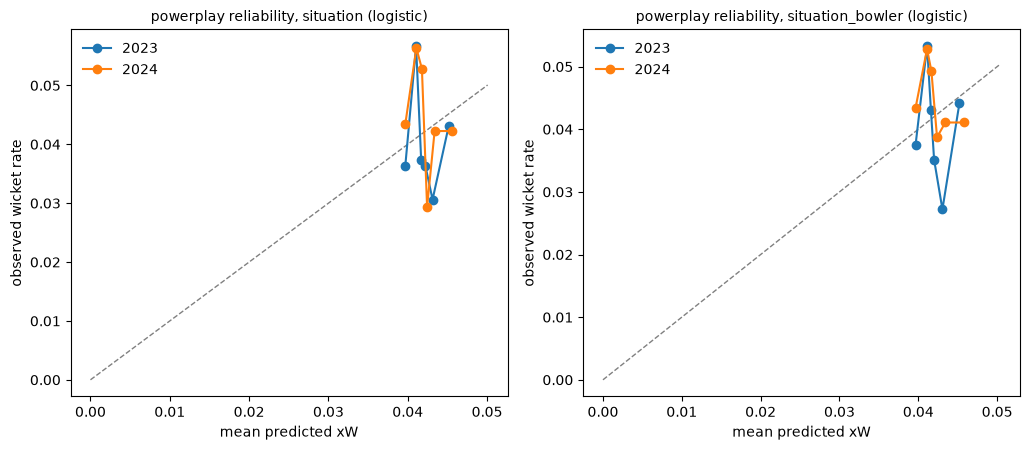

In [6]:
fig, axes = plt.subplots(1, len(run["variants"]), figsize=(5.2 * len(run["variants"]), 4.6), squeeze=False)
for ax, (variant, v) in zip(axes[0], run["variants"].items()):
    rc = v["powerplay_reliability"]
    top = rc["mean_predicted"].max() * 1.1
    ax.plot([0, top], [0, top], "--", color="grey", lw=1)
    for yr, rows in rc.groupby("year"):
        ax.plot(rows["mean_predicted"], rows["observed_rate"], "-o", label=str(yr))
    ax.set_xlabel("mean predicted xW"); ax.set_ylabel("observed wicket rate")
    ax.set_title(f"powerplay reliability, {variant} ({v['chosen_model']})", fontsize=10)
    ax.legend(frameon=False)
fig.tight_layout()
results_io.write_figure(fig, settings, ANALYSIS, "powerplay_reliability_by_season", SEED, PRODUCER)
plt.show()

## The contrast, and the equivalence verdict

Per variant and model: expected and actual powerplay wicket rate per season; the change in each and their gap, with percentile intervals on the shared match draws (`role` marks the carrying model). Then the equivalence verdict for the expected change against the smallest effect of interest, 0.008 wickets per ball (0.3 per 36-ball powerplay).

In [7]:
results_io.write_table(run["contrasts"], settings, ANALYSIS, "powerplay_contrast", SEED, PRODUCER, EXTRA)
results_io.write_table(run["verdicts"], settings, ANALYSIS, "equivalence_verdict", SEED, PRODUCER, EXTRA)
per_season = pd.DataFrame([{"variant": vn, "model": k, "year": yr, **vals}
                           for vn, v in run["variants"].items() for k, c in v["contrasts"].items()
                           for yr, vals in c["per_season"].items()])
results_io.write_table(per_season, settings, ANALYSIS, "powerplay_rates_by_season", SEED, PRODUCER, EXTRA)
display(per_season.round(5))
display(run["contrasts"][["variant", "model", "role", "quantity", "point", "lo", "hi", "lo90", "hi90", "se"]].round(5))
run["verdicts"][["variant", "model", "estimate", "ci90_low", "ci90_high", "ci95_low", "ci95_high", "se", "sesoi", "mde_80pct_power", "verdict"]].round(5)

,variant,model,year,mean_xw,actual_rate
0,situation,hgb,2023,0.04201,0.04006
1,situation,hgb,2024,0.04225,0.04441
2,situation,logistic,2023,0.04216,0.04006
3,situation,logistic,2024,0.04232,0.04441
4,situation_bowler,hgb,2023,0.04200,0.04006
5,situation_bowler,hgb,2024,0.04234,0.04441
6,situation_bowler,logistic,2023,0.04210,0.04006
7,situation_bowler,logistic,2024,0.04233,0.04441


,variant,model,role,quantity,point,lo,hi,lo90,hi90,se
0,situation,hgb,robustness,xw_change,0.00024,-0.00015,0.00063,-0.00009,0.00057,0.00020
1,situation,hgb,robustness,actual_change,0.00434,-0.00229,0.01127,-0.00118,0.01010,0.00345
2,situation,hgb,robustness,gap_xw_minus_actual,-0.00410,-0.01117,0.00268,-0.00998,0.00154,0.00352
3,situation,logistic,carrying,xw_change,0.00016,-0.00015,0.00046,-0.00010,0.00042,0.00016
4,situation,logistic,carrying,actual_change,0.00434,-0.00229,0.01127,-0.00118,0.01010,0.00345
5,situation,logistic,carrying,gap_xw_minus_actual,-0.00418,-0.01118,0.00252,-0.01003,0.00140,0.00349
6,situation_bowler,hgb,robustness,xw_change,0.00034,-0.00009,0.00074,-0.00001,0.00068,0.00021
7,situation_bowler,hgb,robustness,actual_change,0.00434,-0.00229,0.01127,-0.00118,0.01010,0.00345
8,situation_bowler,hgb,robustness,gap_xw_minus_actual,-0.00401,-0.01111,0.00280,-0.00992,0.00167,0.00354
9,situation_bowler,logistic,carrying,xw_change,0.00023,-0.00008,0.00053,-0.00003,0.00049,0.00016


,variant,model,estimate,ci90_low,ci90_high,ci95_low,ci95_high,se,sesoi,mde_80pct_power,verdict
0,situation,logistic,0.00016,-0.00010,0.00042,-0.00015,0.00046,0.00016,0.008,0.00044,equivalent_to_zero
1,situation_bowler,logistic,0.00023,-0.00003,0.00049,-0.00008,0.00053,0.00016,0.008,0.00044,equivalent_to_zero


Expected powerplay wicket rate 0.0421 in 2023 and 0.0423 in 2024, a change of +0.0002 per ball with an interval of −0.0002 to +0.0005, identical across the two variants and the two models. Its 90% interval sits inside the ±0.008 band by an order of magnitude, with a minimum detectable effect of 0.0004: equivalent to zero. The actual rate rose from 0.0401 to 0.0444 (+0.0043, interval −0.0023 to +0.0113), the same reading as the season contrasts, and the gap between actual and expected is −0.004 with an interval of −0.011 to +0.003. The powerplay did not become situationally safer, and adding bowler type changes nothing, so pace deployment is not what kept it safe. The wicket half of the headline holds against the situational loophole.

## Model uncertainty

The fixed-model interval treats the fitted xW as known. Refitting the whole nested pipeline on each of the first 500 shared draws adds the uncertainty of the model itself. Shown: the fixed interval on all draws, the fixed interval on the same 500 draws (so the two are comparable), and the refit interval; `reported` marks the wider.

In [8]:
if len(run["interval_comparison"]):
    results_io.write_table(run["interval_comparison"], settings, ANALYSIS, "fixed_vs_refit_intervals", SEED, PRODUCER, EXTRA)
    display(run["interval_comparison"].round(5))
else:
    print("no refits run: fixed-model intervals are conditional on the fitted model and exclude model uncertainty")

,variant,model,quantity,point,fixed_lo,fixed_hi,fixed_subset_lo,fixed_subset_hi,refit_lo,refit_hi,fixed_width,refit_width,reported
0,situation,logistic,xw_change,0.00016,-0.00015,0.00046,-0.00015,0.00048,-0.00052,0.00039,0.00061,0.00090,refit
1,situation,logistic,actual_change,0.00434,-0.00229,0.01127,-0.00239,0.01088,-0.00239,0.01088,0.01356,0.01327,fixed
2,situation,logistic,gap_xw_minus_actual,-0.00418,-0.01118,0.00252,-0.01068,0.00278,-0.01095,0.00247,0.01370,0.01342,fixed
3,situation_bowler,logistic,xw_change,0.00023,-0.00008,0.00053,-0.00006,0.00054,-0.00049,0.00043,0.00061,0.00092,refit
4,situation_bowler,logistic,actual_change,0.00434,-0.00229,0.01127,-0.00239,0.01088,-0.00239,0.01088,0.01356,0.01327,fixed
5,situation_bowler,logistic,gap_xw_minus_actual,-0.00411,-0.01111,0.00260,-0.01061,0.00286,-0.01102,0.00259,0.01371,0.01361,fixed


The refit interval on the expected change is −0.0005 to +0.0004 against a fixed −0.0002 to +0.0005, about 50% wider and still inside the smallest effect of interest by an order of magnitude; the actual and gap intervals are unchanged. The refit interval is the one to quote.

## Why the expected rate barely moved

With the final model held fixed, the later season's distribution of one feature at a time is substituted into the earlier season's powerplay balls, in random orders, and the change in mean xW attributed to each feature. `full_substitution_change` is the total when every feature is substituted.

In [9]:
decomp = pd.concat([v["decomposition"] for v in run["variants"].values()], ignore_index=True)
results_io.write_table(decomp, settings, ANALYSIS, "feature_mix_decomposition", SEED, PRODUCER, EXTRA)
for variant, v in run["variants"].items():
    print(variant, v["decomposition"].attrs)
decomp.round(6)

situation {'base_mean_xw': 0.042214394579597136, 'full_substitution_change': 0.0006446116629098345}
situation_bowler {'base_mean_xw': 0.04220331861334546, 'full_substitution_change': 0.0011234617020952076}


,variant,feature,contribution,contribution_sd_over_orders
0,situation,required_rate,0.000446,0.000272
1,situation,is_chase,0.000178,0.000285
2,situation,inns_wkts,-0.000022,0.000004
3,situation,inns_balls_rem,0.000021,0.000020
4,situation,bat_is_lhb,0.000016,0.000009
5,situation,over_num,0.000005,0.000024
6,situation_bowler,is_chase,0.000435,0.000387
7,situation_bowler,required_rate,0.000373,0.000417
8,situation_bowler,bowl_is_spin,0.000082,0.000009
9,situation_bowler,inns_balls_rem,0.000028,0.000023


The +0.0006 to +0.0011 total change is almost entirely required run rate and the chase flag (chase situations shifted slightly), with the over and wicket features contributing nothing; with bowler features included, spin adds a small positive and pace a small negative. The null is explained: nothing about the situations teams faced in the 2024 powerplay made wickets more or less likely.

## Did aggressive shots become costlier?

The situation model is blind to what shot was played, by design. This rung regresses the residual (actual minus xW) on faced powerplay balls on aggressive intent, season, and their interaction, under the match bootstrap. The interaction is the change in the extra wicket cost of an aggressive shot between seasons; null or negative means aggressive shots did not become costlier. Shot tags are manual, so the interval is a floor.

In [10]:
rung = pd.concat([v["shot_rung"]["coefficients"] for v in run["variants"].values()], ignore_index=True)
cells = pd.concat([v["shot_rung"]["cell_means"] for v in run["variants"].values()], ignore_index=True)
results_io.write_table(rung, settings, ANALYSIS, "shot_level_rung", SEED, PRODUCER, EXTRA)
results_io.write_table(cells, settings, ANALYSIS, "shot_level_cell_means", SEED, PRODUCER, EXTRA)
display(cells.round(4))
rung.round(4)

,variant,year,aggressive,mean_residual,n
0,situation,2023,0,-0.0099,4495
1,situation,2023,1,0.0418,797
2,situation,2024,0,-0.0068,4335
3,situation,2024,1,0.0514,777
4,situation_bowler,2023,0,-0.0098,4495
5,situation_bowler,2023,1,0.0418,797
6,situation_bowler,2024,0,-0.0068,4335
7,situation_bowler,2024,1,0.0514,777


,variant,coefficient,estimate,se,ci_low,ci_high,p_positive
0,situation,intercept,-0.0099,0.0025,-0.0146,-0.0051,0.0000
1,situation,aggressive,0.0517,0.0094,0.0340,0.0707,1.0000
2,situation,later_season,0.0031,0.0038,-0.0041,0.0106,0.7993
3,situation,aggressive_x_later_season,0.0065,0.0145,-0.0214,0.0349,0.6755
4,situation_bowler,intercept,-0.0098,0.0025,-0.0146,-0.0050,0.0000
5,situation_bowler,aggressive,0.0516,0.0094,0.0340,0.0707,1.0000
6,situation_bowler,later_season,0.0031,0.0038,-0.0042,0.0105,0.7935
7,situation_bowler,aggressive_x_later_season,0.0065,0.0145,-0.0214,0.0349,0.6759


An aggressive shot carries +0.052 residual wickets per ball (interval +0.034 to +0.071) in both seasons; the season interaction is +0.007 with an interval of −0.021 to +0.035 and P(positive) 0.68. Aggressive intent was as costly per shot in 2024 as in 2023, on top of no situational cost. What this does not show is that the *volume* of aggression was free: the cost per aggressive shot was unchanged while the number of them rose, and the actual wicket rate's point estimate did rise, inside an interval that includes zero.

**What this notebook settles.** The powerplay six rate rose about 40% with no measurable wicket cost; the expected wicket rate given situation was equivalent to zero change under two feature sets and two models, and the cost per aggressive shot did not change. The remaining uncertainty is in the actual wicket rate, whose interval is wide, not in the situational or shot-level accounting.

## Fixture check (fixture only)

The fixture's dismissal hazard is a known function of the pre-ball situation, so out-of-fold xW should track it. Skipped on real data.

In [11]:
if USING_FIXTURE:
    from common.synthetic_ballframe import _wicket_hazard
    # data.X rows are the legal deliveries in the feature builder's order; the
    # pre-ball situation it reconstructed is exactly what the fixture hazard reads.
    order = [c for c in ["p_match", "inns", "over_num", "ball", "ball_in_over"] if c in df.columns]
    ordered = df.sort_values(order).reset_index(drop=True)
    legal = ((ordered["wide"] == 0) & (ordered["noball"] == 0)).to_numpy()
    max_balls = ordered.loc[legal, "max_balls"].to_numpy()
    balls_before = max_balls - data.X["inns_balls_rem"].to_numpy()
    rrr = data.X["required_rate"].to_numpy()
    true_hazard = np.array([_wicket_hazard(int(ov), int(bb), int(mb), None if np.isnan(r) else float(r))
                            for ov, bb, mb, r in zip(data.X["over_num"], balls_before, max_balls, rrr)])
    for variant, v in run["variants"].items():
        xw = v["xw"][v["chosen_model"]]
        print(f"{variant}: MAE vs true hazard {np.mean(np.abs(xw - true_hazard)):.4f}  corr {np.corrcoef(xw, true_hazard)[0, 1]:.3f}")
else:
    print("skipped: real data")

skipped: real data
